# SVM Baseline V7 — All Noise Heavy Training → Six Test Conditions

**Project:** Robustness of SLM-Based Sinhala Hate Speech Detection Under Realistic Text Noise

## Experiment scope

This notebook trains **one SVM model** on **All Noise Heavy** training data and evaluates that same fitted model separately on:

1. **All Noise Heavy**
2. **Compound Heavy**
3. **Misspell Heavy**
4. **Clean SOLD**
5. **CodeMix Heavy**
6. **Transliteration Heavy**

There is no Light training, no Light testing, and no Light↔Heavy cross-severity analysis in this experiment.

The SVM methodology remains unchanged:
- character-level TF-IDF (`char_wb`, 1–5 character n-grams)
- TF-IDF inside the `GridSearchCV` pipeline to prevent feature-extraction leakage
- class-balanced SVM
- Linear and RBF kernels
- `C ∈ {0.1, 1, 3, 10}`
- 5-fold stratified CV
- Macro-F1 for model selection


## 2. Imports and Environment Setup

All required packages come pre-installed in Google Colab. `joblib` is used for model persistence, `pathlib` for portable path handling.


In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from datetime import datetime

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
)
from sklearn.dummy import DummyClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Imports OK")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


Imports OK
NumPy: 2.1.3
Pandas: 2.2.3


## 3. Configuration

Edit `OUTPUTS_ROOT` to match your Google Drive layout.

Expected layout:

```text
outputs/
├── train/
│   └── all_noise_heavy.jsonl
└── test/
    ├── all_noise_heavy.jsonl
    ├── compound_heavy.jsonl
    ├── misspell_heavy.jsonl
    ├── clean_sold_test.jsonl
    ├── codemix_heavy.jsonl
    └── transliteration_heavy.jsonl
```

Only the **All Noise Heavy training file** is used for training.

All six test files are evaluated separately using the **same trained model**.


In [2]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [3]:
OUTPUTS_ROOT = "/content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs"

TRAIN_CONDITION = "all_noise_heavy"
TRAIN_FILE = f"{OUTPUTS_ROOT}/train/all_noise_heavy.jsonl"

TEST_FILES = {
    "all_noise_heavy": f"{OUTPUTS_ROOT}/test/all_noise_heavy.jsonl",
    "compound_heavy": f"{OUTPUTS_ROOT}/test/compound_heavy.jsonl",
    "misspell_heavy": f"{OUTPUTS_ROOT}/test/misspell_heavy.jsonl",
    "clean_sold": f"{OUTPUTS_ROOT}/test/clean_sold_test.jsonl",
    "codemix_heavy": f"{OUTPUTS_ROOT}/test/codemix_heavy.jsonl",
    "transliteration_heavy": f"{OUTPUTS_ROOT}/test/transliteration_heavy.jsonl",
}

OUT_DIR = (
    "/content/drive/MyDrive/"
    "Sinhala-Noisy-Hatespeech-Data/"
    "svm_artifacts/all_noise_heavy_train_all_noise_tests"
)

TEXT_COL = "noisy_text"
LABEL_COL = "label"
LABEL_NAMES = ["not_offensive", "offensive"]

Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

print("TRAIN_CONDITION:", TRAIN_CONDITION)
print("OUTPUTS_ROOT   :", OUTPUTS_ROOT)
print("TRAIN_FILE     :", TRAIN_FILE)
print("OUT_DIR        :", OUT_DIR)
print()

for condition, path in {"all_noise_heavy_train": TRAIN_FILE, **TEST_FILES}.items():
    p = Path(path)
    print(f"{condition:28s} -> {p} | exists={p.exists()}")
    if not p.exists():
        raise FileNotFoundError(f"Required dataset not found: {p}")


TRAIN_CONDITION: all_noise_heavy
OUTPUTS_ROOT   : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs
TRAIN_FILE     : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/train/all_noise_heavy.jsonl
OUT_DIR        : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/all_noise_heavy_train_all_noise_tests

all_noise_heavy_train        -> /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/train/all_noise_heavy.jsonl | exists=True
all_noise_heavy              -> /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/all_noise_heavy.jsonl | exists=True
compound_heavy               -> /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/compound_heavy.jsonl | exists=True
misspell_heavy               -> /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/misspell_heavy.jsonl | exists=True
clean_sold                   -> /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/clean_sold_test.jsonl | exi

## 4. Dataset Loading

This experiment uses one training file and six test files:

- `all_noise_heavy.jsonl` — **training**
- `all_noise_heavy.jsonl` — **test**
- `compound_heavy.jsonl` — **test**
- `misspell_heavy.jsonl` — **test**
- `clean_sold_test.jsonl` — **test**
- `codemix_heavy.jsonl` — **test**
- `transliteration_heavy.jsonl` — **test**

The clean SOLD dataset has no Light/Heavy severity, so it is represented only by its clean test split.

No test dataset is used during SVM hyperparameter selection.


In [4]:
def load_jsonl(path: str) -> pd.DataFrame:
    """Load a JSONL file into a DataFrame, skipping blank lines."""
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))

    if not rows:
        raise ValueError(f"Dataset is empty: {path}")

    return pd.DataFrame(rows)


train_df = load_jsonl(TRAIN_FILE)
test_data = {
    condition: load_jsonl(path)
    for condition, path in TEST_FILES.items()
}

# CodeMix/transliteration/noise datasets use noisy_text.
# Clean SOLD may use text, so canonicalize it to TEXT_COL.
if "clean_sold" in test_data and TEXT_COL not in test_data["clean_sold"].columns and "text" in test_data["clean_sold"].columns:
    test_data["clean_sold"] = test_data["clean_sold"].rename(columns={"text": TEXT_COL})

train_df[TEXT_COL] = train_df[TEXT_COL].astype(str)
train_df[LABEL_COL] = train_df[LABEL_COL].astype(int)

for condition, df in test_data.items():
    if TEXT_COL not in df.columns:
        raise KeyError(
            f"{condition} test dataset does not contain '{TEXT_COL}'. "
            f"Available columns: {list(df.columns)}"
        )
    df[TEXT_COL] = df[TEXT_COL].astype(str)
    df[LABEL_COL] = df[LABEL_COL].astype(int)
    test_data[condition] = df.reset_index(drop=True)

train_df = train_df.reset_index(drop=True)

print(f"All Noise Heavy TRAIN          : {len(train_df):,} rows")
for condition, df in test_data.items():
    print(f"{condition:30s}: {len(df):,} rows")


All Noise Heavy TRAIN          : 7,500 rows
all_noise_heavy               : 2,500 rows
compound_heavy                : 2,500 rows
misspell_heavy                : 2,500 rows
clean_sold                    : 2,500 rows
codemix_heavy                 : 2,500 rows
transliteration_heavy         : 2,500 rows


## 5. Dataset Validation

Before training, verify every split for:
- Required column presence
- Missing values
- Class distribution and balance
- Duplicate texts (informational only — not removed, as duplicates may be genuine)


In [5]:
def validate_dataset(df: pd.DataFrame, condition_name: str, split_type: str) -> None:
    """
    Validates a dataset for required columns, missing values, class distribution,
    and duplicate texts.
    """
    print(f"\n{'='*70}")
    print(f"  VALIDATING {split_type.upper()} DATASET: {condition_name.upper()}")
    print(f"{'='*70}")

    # 1. Required column presence
    required_cols = [TEXT_COL, LABEL_COL]
    if split_type == "train":
        # Assuming source_id is required for train for leakage checks later
        required_cols.append("source_id")

    missing_cols = [col for col in required_cols if col not in df.columns]
    if missing_cols:
        raise ValueError(
            f"Dataset '{condition_name}' is missing required columns: {missing_cols}"
        )
    print(f"✓ All required columns present: {required_cols}")

    # 2. Missing values
    for col in required_cols:
        if df[col].isnull().any():
            null_count = df[col].isnull().sum()
            raise ValueError(
                f"Dataset '{condition_name}' has {null_count} missing values in '{col}'."
            )
    print(f"✓ No missing values in required columns.")

    # 3. Class distribution and balance
    print(f"\nClass Distribution for '{condition_name}':")
    class_counts = df[LABEL_COL].value_counts()
    total_samples = len(df)
    for label, count in class_counts.items():
        percentage = (count / total_samples) * 100
        print(f"  Label {label} ({LABEL_NAMES[label]}): {count:,} samples ({percentage:.2f}%)")

    # Check for extreme imbalance (optional, but good for validation)
    if len(class_counts) > 1:
        ratio = class_counts.min() / class_counts.max()
        if ratio < 0.1: # Example threshold for "extreme" imbalance
            print(f"WARNING: Extreme class imbalance detected (ratio min/max: {ratio:.2f}).")
    else:
        print(f"WARNING: Only one class ({class_counts.index[0]}) present in '{condition_name}'.")

    # 4. Duplicate texts (informational only)
    duplicate_texts_count = df[TEXT_COL].duplicated().sum()
    if duplicate_texts_count > 0:
        print(
            f"\nINFO: {duplicate_texts_count:,} duplicate texts found in '{condition_name}'. "
            "These are not removed for this experiment."
        )
    else:
        print("\n✓ No duplicate texts found.")

    print(f"✓ Validation for '{condition_name}' completed.")


# Validate the single training dataset and all six test datasets.

validate_dataset(train_df, "all_noise_heavy", "train")

for condition, df in test_data.items():
    validate_dataset(df, condition, "test")


  VALIDATING TRAIN DATASET: ALL_NOISE_HEAVY
✓ All required columns present: ['noisy_text', 'label', 'source_id']
✓ No missing values in required columns.

Class Distribution for 'all_noise_heavy':
  Label 0 (not_offensive): 4,324 samples (57.65%)
  Label 1 (offensive): 3,176 samples (42.35%)

✓ No duplicate texts found.
✓ Validation for 'all_noise_heavy' completed.

  VALIDATING TEST DATASET: ALL_NOISE_HEAVY
✓ All required columns present: ['noisy_text', 'label']
✓ No missing values in required columns.

Class Distribution for 'all_noise_heavy':
  Label 0 (not_offensive): 1,485 samples (59.40%)
  Label 1 (offensive): 1,015 samples (40.60%)

✓ No duplicate texts found.
✓ Validation for 'all_noise_heavy' completed.

  VALIDATING TEST DATASET: COMPOUND_HEAVY
✓ All required columns present: ['noisy_text', 'label']
✓ No missing values in required columns.

Class Distribution for 'compound_heavy':
  Label 0 (not_offensive): 1,485 samples (59.40%)
  Label 1 (offensive): 1,015 samples (40.60%

## 5.1. Test Conditions

No cross-severity alignment is required for this experiment.

| Training | Test | Purpose |
|---|---|---|
| All Noise Heavy | All Noise Heavy | Cross-noise robustness |
| All Noise Heavy | Compound Heavy | Cross-noise robustness |
| All Noise Heavy | Misspell Heavy | Cross-noise robustness |
| All Noise Heavy | Clean SOLD | Transfer to clean text |
| All Noise Heavy | CodeMix Heavy | Cross-noise robustness |
| All Noise Heavy | Transliteration Heavy | Cross-noise robustness |

Only the Heavy versions are used for the noisy test conditions.


In [6]:
# No Light/Heavy alignment check is performed in this experiment.
print("Cross-severity alignment check: NOT APPLICABLE")
print("This experiment uses Heavy All training and six fixed test conditions.")


Cross-severity alignment check: NOT APPLICABLE
This experiment uses Heavy All training and six fixed test conditions.


## 5.2. Train/Test Source-ID Leakage Check

The **All Noise Heavy training set** must not share underlying `source_id` values with any of the six test sets.

The check is performed separately for `All Noise Heavy train → each test condition`.

If `source_id` is unavailable in a dataset, the notebook reports that source-ID leakage cannot be checked for that dataset rather than inventing an identifier.


In [7]:
def validate_train_test_source_separation() -> None:
    print("\n" + "=" * 70)
    print("  TRAIN/TEST SOURCE-ID LEAKAGE CHECK")
    print("=" * 70)

    if "source_id" not in train_df.columns:
        print(
            "WARNING: source_id is not available in All Noise Heavy training data. "
            "ID-based leakage checking cannot be performed."
        )
        return

    train_ids = set(train_df["source_id"].astype(str))

    for test_condition, test_df in test_data.items():
        if "source_id" not in test_df.columns:
            print(
                f"WARNING: source_id is not available in {test_condition} test data. "
                "ID-based leakage checking cannot be performed for this condition."
            )
            continue

        test_ids = set(test_df["source_id"].astype(str))
        overlap = train_ids & test_ids

        print(
            f"All Noise Heavy train ∩ {test_condition} test : "
            f"{len(overlap):,} overlapping source IDs"
        )

        if overlap:
            examples = sorted(overlap)[:10]
            raise AssertionError(
                f"Source-ID overlap detected between All Noise Heavy training and "
                f"{test_condition} test. Example IDs: {examples}"
            )

    print("\n✓ Source-ID leakage checks completed.")


validate_train_test_source_separation()



  TRAIN/TEST SOURCE-ID LEAKAGE CHECK
All Noise Heavy train ∩ all_noise_heavy test : 0 overlapping source IDs
All Noise Heavy train ∩ compound_heavy test : 0 overlapping source IDs
All Noise Heavy train ∩ misspell_heavy test : 0 overlapping source IDs
All Noise Heavy train ∩ codemix_heavy test : 0 overlapping source IDs
All Noise Heavy train ∩ transliteration_heavy test : 0 overlapping source IDs

✓ Source-ID leakage checks completed.


## 6. Class Distribution Analysis

The SOLD dataset has a mild class imbalance (~41 % offensive). This motivates:
1. Macro-F1 as the primary metric (treats both classes equally).
2. `class_weight="balanced"` inside SVM to avoid the model defaulting to the majority class.


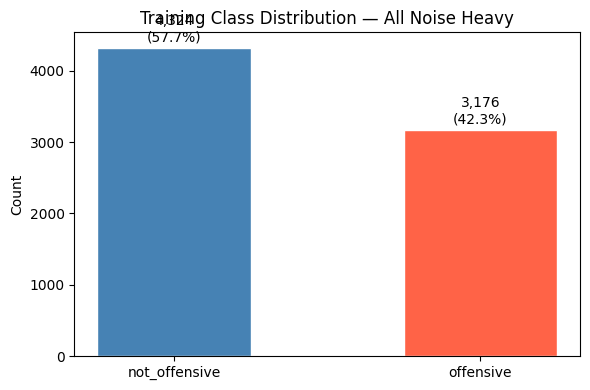

In [8]:
counts = train_df[LABEL_COL].value_counts().rename(
    {0: "not_offensive", 1: "offensive"}
)

plt.figure(figsize=(6, 4))
bars = plt.bar(counts.index, counts.values,
               color=["steelblue", "tomato"],
               edgecolor="white", width=0.5)

plt.title("Training Class Distribution — All Noise Heavy")
plt.ylabel("Count")

for bar, (label, val) in zip(bars, counts.items()):
    pct = 100 * val / len(train_df)
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f"{val:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. SVM Feature Representation

**Primary representation: character-level TF-IDF with 1–5 character n-grams.**

| Parameter | Value | Rationale |
|---|---|---|
| `analyzer` | `char_wb` | Character n-grams constrained to word boundaries |
| `ngram_range` | `(1, 5)` | Captures single chars up to 5-char patterns; aligns with proposal |
| `min_df` | `2` | Filters hapax n-grams, reducing noise from one-off code-mixing variants |
| `sublinear_tf` | `True` | Log-scales raw TF, preventing high-frequency n-grams from dominating |

**Important:** The vectorizer is placed *inside* the scikit-learn `Pipeline` and is
therefore fitted **within each cross-validation training fold**. This prevents any test-set
information from leaking into the feature vocabulary or IDF statistics.


## 8. SVM Pipeline

The `Pipeline` object chains TF-IDF and SVM into a single estimator.
This ensures the vectorizer is refitted from scratch on each cross-validation
training fold — a critical requirement for valid hyperparameter selection.

```
Raw text
   │
   ▼
TfidfVectorizer(analyzer="char_wb", ngram_range=(1,5), ...)
   │
   ▼
SVC(class_weight="balanced", ...)
   │
   ▼
Prediction (0 = not_offensive, 1 = offensive)
```


**Kernel selection:** The SVM kernel is selected by `GridSearchCV`; both `linear` and `rbf` are evaluated together with the C values in the grid.

In [9]:
def build_svm_pipeline() -> Pipeline:
    """
    Build the primary SVM pipeline: character TF-IDF (1-5) -> SVC.

    The pipeline is the object passed to GridSearchCV so that the TF-IDF
    vocabulary and IDF statistics are learned *within* each CV fold, never
    on the test set.
    """
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(1, 5),
            min_df=2,
            sublinear_tf=True,
        )),
        ("svm", SVC(
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ])


print("SVM pipeline defined:")
print(build_svm_pipeline())


SVM pipeline defined:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(analyzer='char_wb', min_df=2,
                                 ngram_range=(1, 5), sublinear_tf=True)),
                ('svm', SVC(class_weight='balanced', random_state=42))])


## 9. Hyperparameter Tuning

**Search strategy:** `GridSearchCV` over a small, principled grid.

**Parameters tuned:**

| Parameter | Values | Notes |
|---|---|---|
| `svm__kernel` | `linear`, `rbf` | Linear is efficient for sparse TF-IDF; RBF can capture nonlinear decision boundaries |
| `svm__C` | `0.1, 1, 3, 10` | Regularisation parameter; larger values penalise training errors more strongly |

**CV setup:**
- 5-fold stratified cross-validation
- Scored on **macro-F1** (equal weight to both classes)
- The complete TF-IDF + SVM pipeline is passed to `GridSearchCV`
- Test data is never seen during hyperparameter tuning

**Computational note:** 2 kernels × 4 C values × 5 folds = 40 SVM fits per severity.
This is intentionally more expensive than the linear-only version because kernel type is
now tuned as specified in the proposal.


### Computational note

This notebook evaluates both **Linear and RBF SVM kernels**. The grid remains deliberately small:

- `kernel ∈ {linear, rbf}`
- `C ∈ {0.1, 1, 3, 10}`

Five-fold stratified cross-validation is retained, and TF-IDF remains inside the Pipeline. This preserves the refined SVM methodology while allowing the RBF kernel to be selected when it provides better CV Macro-F1.


In [10]:
SVM_PARAM_GRID = {
    "svm__kernel": ["linear", "rbf"],
    "svm__C":      [0.1, 1, 3, 10],
}


## 10 & 11. Train the All Noise Heavy SVM

Only **All Noise Heavy training data** is used.

A single SVM is trained using 5-fold stratified GridSearchCV. The best pipeline is then reused for all six test conditions.


In [11]:
def train_svm_all_noise_heavy() -> dict:
    """Train one SVM on All Noise Heavy training data via GridSearchCV."""
    print(f"\n{'='*70}")
    print("  Training SVM — ALL NOISE HEAVY")
    print(f"{'='*70}")

    X_train = train_df[TEXT_COL].values
    y_train = train_df[LABEL_COL].values

    n_pos = (y_train == 1).sum()
    n_neg = (y_train == 0).sum()

    print(
        f"Training samples : {len(y_train):,} "
        f"(not_offensive={n_neg}, offensive={n_pos})"
    )

    pipeline = build_svm_pipeline()

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=SVM_PARAM_GRID,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        verbose=1,
        return_train_score=False,
    )
    search.fit(X_train, y_train)

    print(f"\nBest params      : {search.best_params_}")
    print(f"Best CV Macro-F1 : {search.best_score_:.4f}")

    return {
        "condition": "all_noise_heavy",
        "pipeline": search.best_estimator_,
        "best_params": search.best_params_,
        "cv_macro_f1": search.best_score_,
        "train_size": len(y_train),
        "timestamp": datetime.now().isoformat(timespec="seconds"),
    }


trained_model = train_svm_all_noise_heavy()

print("\n✓ All Noise Heavy SVM trained.")
print("Best parameters:", trained_model["best_params"])
print("CV Macro-F1:", f"{trained_model['cv_macro_f1']:.4f}")



  Training SVM — ALL NOISE HEAVY
Training samples : 7,500 (not_offensive=4324, offensive=3176)
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best params      : {'svm__C': 3, 'svm__kernel': 'rbf'}
Best CV Macro-F1 : 0.7755

✓ All Noise Heavy SVM trained.
Best parameters: {'svm__C': 3, 'svm__kernel': 'rbf'}
CV Macro-F1: 0.7755


## 12 & 13. Evaluation — All Noise Heavy Model on Six Test Conditions

The **same trained All Noise Heavy SVM** is evaluated independently on:

| Train | Test | Interpretation |
|---|---|---|
| All Noise Heavy | All Noise Heavy | Cross-noise robustness |
| All Noise Heavy | Compound Heavy | Cross-noise robustness |
| All Noise Heavy | Misspell Heavy | Cross-noise robustness |
| All Noise Heavy | Clean SOLD | Transfer to clean text |
| All Noise Heavy | CodeMix Heavy | Cross-noise robustness |
| All Noise Heavy | Transliteration Heavy | Cross-noise robustness |

There is no retraining between evaluations.


In [12]:
def evaluate_model(artifact: dict, test_condition: str) -> tuple:
    """Evaluate the fitted All Noise Heavy SVM on one test condition."""
    pipeline = artifact["pipeline"]

    test_df = test_data[test_condition].copy().reset_index(drop=True)
    X_test = test_df[TEXT_COL].values
    y_true = test_df[LABEL_COL].values

    y_pred = pipeline.predict(X_test)
    decision_scores = pipeline.decision_function(X_test)

    acc = accuracy_score(y_true, y_pred)
    balanced_acc = balanced_accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    prec, rec, f1_per, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    train_labels = train_df[LABEL_COL].astype(int).values
    majority_class = int(pd.Series(train_labels).mode().iloc[0])
    minority_class = 1 - majority_class

    majority_pred = np.full(len(y_true), majority_class, dtype=int)
    minority_pred = np.full(len(y_true), minority_class, dtype=int)

    majority_macro_f1 = f1_score(
        y_true, majority_pred, average="macro", zero_division=0
    )
    minority_macro_f1 = f1_score(
        y_true, minority_pred, average="macro", zero_division=0
    )

    preds_df = test_df.copy()
    preds_df["predicted_label"] = y_pred
    preds_df["actual_label"] = y_true
    preds_df["correct"] = y_pred == y_true
    preds_df["decision_score"] = decision_scores

    print(f"\n{'='*70}")
    print(f"  Train: ALL NOISE HEAVY  →  Test: {test_condition.upper()}")
    print(f"{'='*70}")
    print(f"Accuracy        : {acc:.4f}")
    print(f"Balanced Accuracy : {balanced_acc:.4f}")
    print(f"CV Macro-F1     : {artifact["cv_macro_f1"]:.4f}")
    print(f"Macro-F1        : {macro_f1:.4f}   ← primary metric")
    print(f"Weighted-F1     : {weighted_f1:.4f}")
    print()
    print(classification_report(
        y_true, y_pred, target_names=LABEL_NAMES, digits=4, zero_division=0
    ))
    print(f">>> OFFENSIVE-CLASS RECALL = {rec[1]:.4f} <<<")
    print()
    print(f"Majority baseline ({majority_class}) macro-F1 : {majority_macro_f1:.4f}")
    print(f"Minority baseline ({minority_class}) macro-F1 : {minority_macro_f1:.4f}")

    result = {
        "training_condition": "all_noise_heavy",
        "testing_condition": test_condition,
        "accuracy": acc,
        "balanced_accuracy": balanced_acc,
        "macro_f1": macro_f1,
        "cv_macro_f1": artifact["cv_macro_f1"],
        "weighted_f1": weighted_f1,
        "precision_not_offensive": prec[0],
        "recall_not_offensive": rec[0],
        "f1_not_offensive": f1_per[0],
        "precision_offensive": prec[1],
        "recall_offensive": rec[1],
        "f1_offensive": f1_per[1],
        "support_not_offensive": int(support[0]),
        "support_offensive": int(support[1]),
        "majority_class": majority_class,
        "minority_class": minority_class,
        "majority_baseline_macro_f1": majority_macro_f1,
        "minority_baseline_macro_f1": minority_macro_f1,
        "beats_majority_baseline": macro_f1 > majority_macro_f1,
        "beats_minority_baseline": macro_f1 > minority_macro_f1,
        "cv_macro_f1": artifact["cv_macro_f1"],
        "best_params": str(artifact["best_params"]),
    }

    return result, cm, preds_df


In [13]:
all_results = []
all_cms = {}
all_preds = {}

EVAL_CONDITIONS = ['all_noise_heavy', 'compound_heavy', 'misspell_heavy', 'clean_sold', 'codemix_heavy', 'transliteration_heavy']

for test_condition in EVAL_CONDITIONS:
    result, cm, preds_df = evaluate_model(trained_model, test_condition)
    key = f"all_noise_heavy_train__{test_condition}_test"
    all_results.append(result)
    all_cms[key] = cm
    all_preds[key] = preds_df

print(f"\n✓ All {len(EVAL_CONDITIONS)} evaluation conditions completed.")



  Train: ALL NOISE HEAVY  →  Test: ALL_NOISE_HEAVY
Accuracy        : 0.7700
Balanced Accuracy : 0.7475
CV Macro-F1     : 0.7755
Macro-F1        : 0.7533   ← primary metric
Weighted-F1     : 0.7653

               precision    recall  f1-score   support

not_offensive     0.7731    0.8673    0.8175      1485
    offensive     0.7638    0.6276    0.6890      1015

     accuracy                         0.7700      2500
    macro avg     0.7684    0.7475    0.7533      2500
 weighted avg     0.7693    0.7700    0.7653      2500

>>> OFFENSIVE-CLASS RECALL = 0.6276 <<<

Majority baseline (0) macro-F1 : 0.3726
Minority baseline (1) macro-F1 : 0.2888

  Train: ALL NOISE HEAVY  →  Test: COMPOUND_HEAVY
Accuracy        : 0.7928
Balanced Accuracy : 0.7748
CV Macro-F1     : 0.7755
Macro-F1        : 0.7800   ← primary metric
Weighted-F1     : 0.7900

               precision    recall  f1-score   support

not_offensive     0.7986    0.8707    0.8331      1485
    offensive     0.7821    0.6788    

## 15. Majority- and Minority-Class Baselines

Baseline classes are derived from the **All Noise Heavy training labels only**.

Test labels are never used to determine which class is the majority or minority baseline.


In [14]:
print("Baseline macro-F1 vs SVM macro-F1\n")
print(f"{'Test':28s} {'Majority':>12s} {'Minority':>12s} {'SVM':>10s}")
print("-" * 68)

for r in all_results:
    print(
        f"{r['testing_condition']:28s} "
        f"{r['majority_baseline_macro_f1']:12.4f} "
        f"{r['minority_baseline_macro_f1']:12.4f} "
        f"{r['macro_f1']:10.4f}"
    )


Baseline macro-F1 vs SVM macro-F1

Test                             Majority     Minority        SVM
--------------------------------------------------------------------
all_noise_heavy                    0.3726       0.2888     0.7533
compound_heavy                     0.3726       0.2888     0.7800
misspell_heavy                     0.3726       0.2888     0.7817
clean_sold                         0.3726       0.2888     0.7886
codemix_heavy                      0.3726       0.2888     0.7821
transliteration_heavy              0.3726       0.2888     0.7760


## 15. Confusion Matrices

One confusion matrix is produced for each of the six test conditions.

Rows = actual label; columns = predicted label.


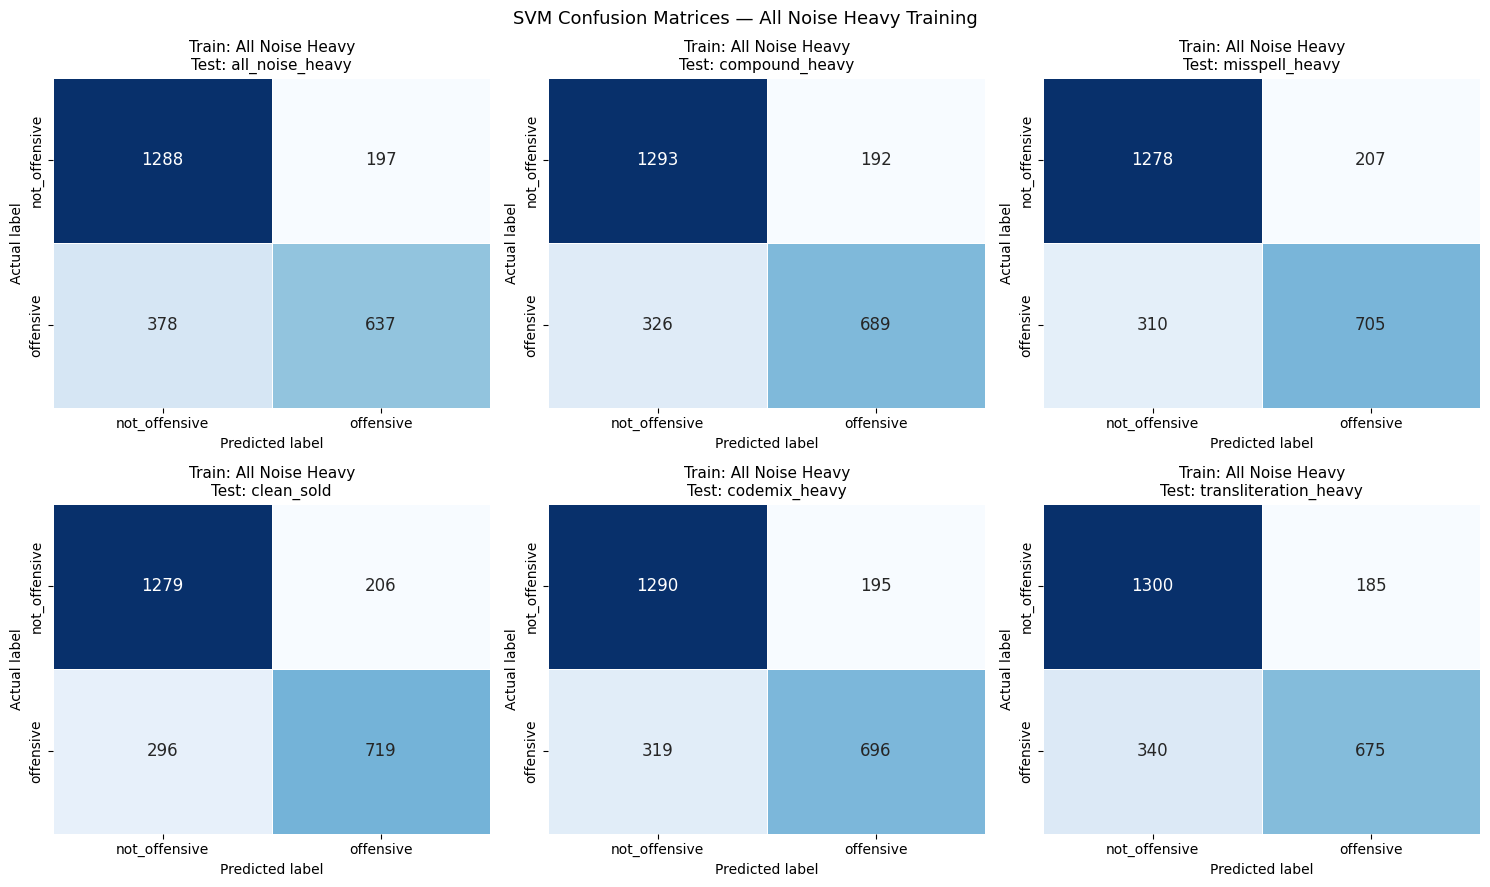

In [15]:
ncols = 3
nrows = int(np.ceil(len(EVAL_CONDITIONS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
axes = np.array(axes).reshape(-1)

for ax, test_condition in zip(axes, EVAL_CONDITIONS):
    key = f"all_noise_heavy_train__{test_condition}_test"
    cm = all_cms[key]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=LABEL_NAMES,
        yticklabels=LABEL_NAMES,
        ax=ax,
        cbar=False,
        linewidths=0.5,
        annot_kws={"size": 12},
    )

    ax.set_title(f"Train: All Noise Heavy\nTest: {test_condition}", fontsize=11)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

for ax in axes[len(EVAL_CONDITIONS):]:
    ax.axis("off")

plt.suptitle("SVM Confusion Matrices — All Noise Heavy Training", fontsize=13)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()


## 16. Performance Comparison Across Test Conditions

This experiment does **not** calculate Light→Heavy degradation because no Light model or Light test set is used.

Instead, the six results show how a model trained on All Noise Heavy transfers across:
1. All Noise Heavy,
2. Compound Heavy,
3. Misspell Heavy,
4. Clean SOLD,
5. CodeMix Heavy, and
6. Transliteration Heavy.


In [16]:
results_df = pd.DataFrame(all_results)

metrics = ["accuracy", "balanced_accuracy", "macro_f1", "cv_macro_f1", "weighted_f1", "recall_offensive", "recall_not_offensive"]
metric_labels = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced Accuracy",
    "cv_macro_f1": "CV Macro-F1",
    "macro_f1": "Macro-F1",
    "weighted_f1": "Weighted-F1",
    "recall_offensive": "Offensive Recall",
    "recall_not_offensive": "Not-Offensive Recall",
}

print("Performance comparison: All Noise Heavy training → six test conditions\n")
print(
    f"{'Test condition':<28s} "
    + " ".join(f"{metric_labels[m]:>18s}" for m in metrics)
)
print("-" * 120)

for _, r in results_df.iterrows():
    print(
        f"{r['testing_condition']:<28s} "
        + " ".join(f"{r[m]:18.4f}" for m in metrics)
    )


Performance comparison: All Noise Heavy training → six test conditions

Test condition                         Accuracy  Balanced Accuracy           Macro-F1        CV Macro-F1        Weighted-F1   Offensive Recall Not-Offensive Recall
------------------------------------------------------------------------------------------------------------------------
all_noise_heavy                          0.7700             0.7475             0.7533             0.7755             0.7653             0.6276             0.8673
compound_heavy                           0.7928             0.7748             0.7800             0.7755             0.7900             0.6788             0.8707
misspell_heavy                           0.7932             0.7776             0.7817             0.7755             0.7911             0.6946             0.8606
clean_sold                               0.7992             0.7848             0.7886             0.7755             0.7975             0.7084             0.

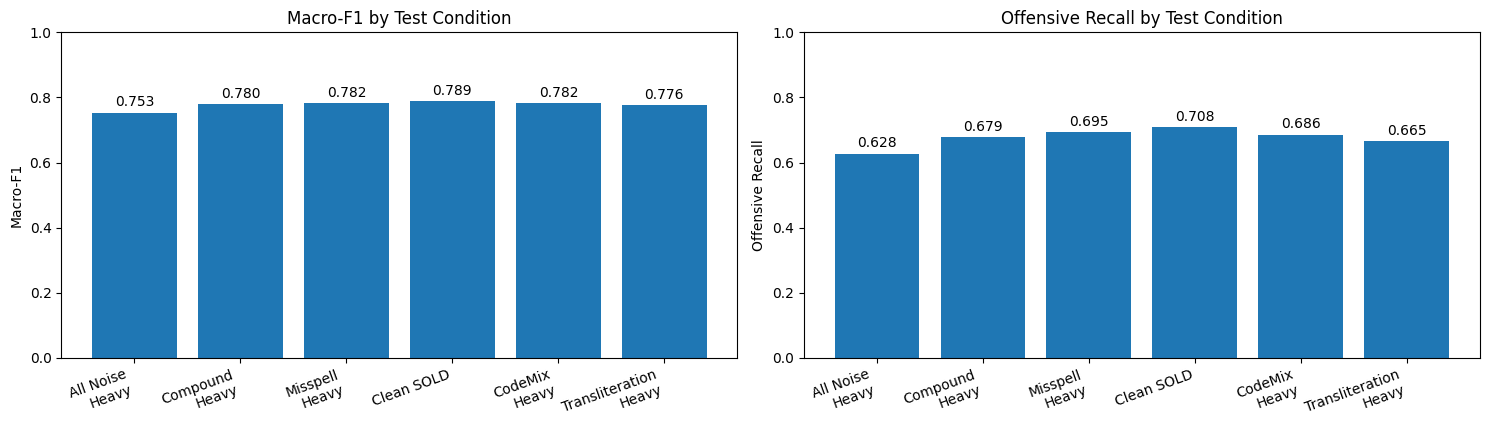

In [17]:
labels = ['All Noise\nHeavy', 'Compound\nHeavy', 'Misspell\nHeavy', 'Clean SOLD', 'CodeMix\nHeavy', 'Transliteration\nHeavy']
x = np.arange(len(EVAL_CONDITIONS))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

for ax, metric, title in [
    (axes[0], "macro_f1", "Macro-F1"),
    (axes[1], "recall_offensive", "Offensive Recall"),
]:
    values = results_df[metric].values
    bars = ax.bar(x, values)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=20, ha="right")
    ax.set_ylim(0, 1)
    ax.set_ylabel(title)
    ax.set_title(f"{title} by Test Condition")

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.01,
            f"{value:.3f}",
            ha="center",
            va="bottom",
        )

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/performance_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


## 17. Offensive-Class Recall Analysis

This section compares offensive and not-offensive recall across the six independent test conditions.


In [18]:
print("Offensive-Class Analysis\n")
print(
    f"{'Test':28s} {'Off. Prec':>11s} {'Off. Rec':>10s} "
    f"{'Off. F1':>9s} {'Not-Off. Rec':>14s} {'Rec Diff':>10s}"
)
print("-" * 90)

for _, r in results_df.iterrows():
    rec_diff = r["recall_offensive"] - r["recall_not_offensive"]
    print(
        f"{r['testing_condition']:28s} "
        f"{r['precision_offensive']:11.4f} "
        f"{r['recall_offensive']:10.4f} "
        f"{r['f1_offensive']:9.4f} "
        f"{r['recall_not_offensive']:14.4f} "
        f"{rec_diff:+10.4f}"
    )

print()
print("Rec Diff = Offensive Recall − Not-Offensive Recall")
print("Negative values indicate relatively weaker offensive-class detection.")


Offensive-Class Analysis

Test                           Off. Prec   Off. Rec   Off. F1   Not-Off. Rec   Rec Diff
------------------------------------------------------------------------------------------
all_noise_heavy                   0.7638     0.6276    0.6890         0.8673    -0.2398
compound_heavy                    0.7821     0.6788    0.7268         0.8707    -0.1919
misspell_heavy                    0.7730     0.6946    0.7317         0.8606    -0.1660
clean_sold                        0.7773     0.7084    0.7412         0.8613    -0.1529
codemix_heavy                     0.7811     0.6857    0.7303         0.8687    -0.1830
transliteration_heavy             0.7849     0.6650    0.7200         0.8754    -0.2104

Rec Diff = Offensive Recall − Not-Offensive Recall
Negative values indicate relatively weaker offensive-class detection.


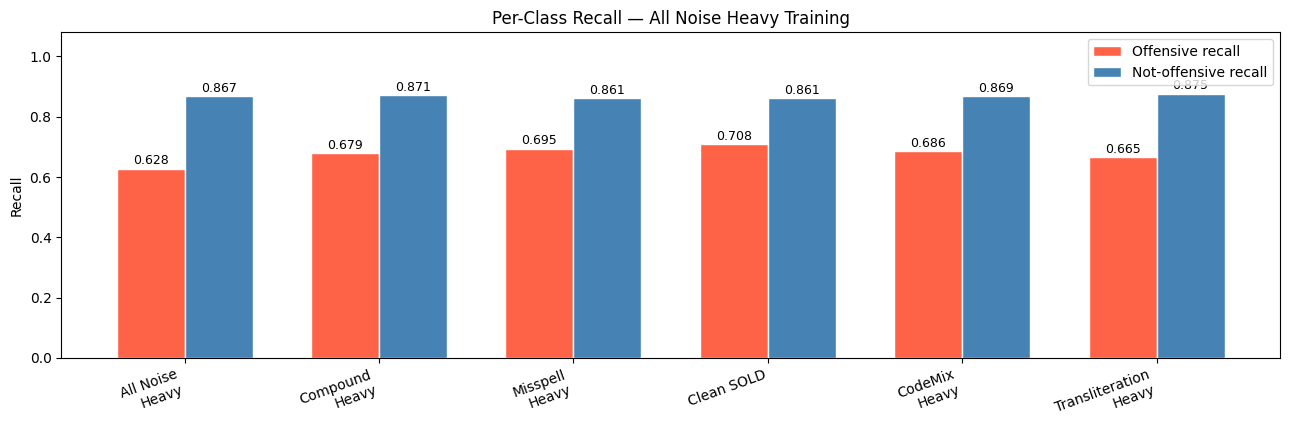

In [19]:
fig, ax = plt.subplots(figsize=(13, 4.5))

x = np.arange(len(EVAL_CONDITIONS))
w = 0.35
labels = ['All Noise\nHeavy', 'Compound\nHeavy', 'Misspell\nHeavy', 'Clean SOLD', 'CodeMix\nHeavy', 'Transliteration\nHeavy']

bars1 = ax.bar(
    x - w / 2,
    results_df["recall_offensive"],
    width=w,
    color="tomato",
    label="Offensive recall",
    edgecolor="white",
)
bars2 = ax.bar(
    x + w / 2,
    results_df["recall_not_offensive"],
    width=w,
    color="steelblue",
    label="Not-offensive recall",
    edgecolor="white",
)

for bar in list(bars1) + list(bars2):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{bar.get_height():.3f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=20, ha="right")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1.08)
ax.set_title("Per-Class Recall — All Noise Heavy Training")
ax.legend()

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/offensive_recall_analysis.png", dpi=150, bbox_inches="tight")
plt.show()


## 18. Error Analysis

For each of the six test conditions, examine:

- **False Negatives:** offensive posts the model missed.
- **False Positives:** not-offensive posts incorrectly flagged.

Borderline errors (decision score closest to zero) are shown first.


In [20]:
def show_errors(preds_df: pd.DataFrame, test_condition: str, n: int = 10) -> None:
    """Display false-negative and false-positive examples."""
    print(f"\n{'='*70}")
    print(f"  Error Analysis — Train: ALL NOISE HEAVY | Test: {test_condition.upper()}")
    print(f"{'='*70}")

    fn = preds_df[
        (preds_df["actual_label"] == 1) &
        (preds_df["predicted_label"] == 0)
    ].copy()
    fn["abs_decision_score"] = fn["decision_score"].abs()
    fn = fn.sort_values("abs_decision_score", ascending=True)

    print(f"\nFALSE NEGATIVES — {len(fn):,} total; showing {min(n, len(fn))}:")
    for _, row in fn.head(n).iterrows():
        print(f"  text: {str(row[TEXT_COL])[:120]}")
        print(f"  decision_score: {row['decision_score']:.4f}\n")

    fp = preds_df[
        (preds_df["actual_label"] == 0) &
        (preds_df["predicted_label"] == 1)
    ].copy()
    fp["abs_decision_score"] = fp["decision_score"].abs()
    fp = fp.sort_values("abs_decision_score", ascending=True)

    print(f"FALSE POSITIVES — {len(fp):,} total; showing {min(n, len(fp))}:")
    for _, row in fp.head(n).iterrows():
        print(f"  text: {str(row[TEXT_COL])[:120]}")
        print(f"  decision_score: {row['decision_score']:.4f}\n")


for test_condition in EVAL_CONDITIONS:
    key = f"all_noise_heavy_train__{test_condition}_test"
    show_errors(all_preds[key], test_condition, n=5)



  Error Analysis — Train: ALL NOISE HEAVY | Test: ALL_NOISE_HEAVY

FALSE NEGATIVES — 378 total; showing 5:
  text: @USER  @USER samarawita apsarawonta yanna lift ekak thiyenna ati. e naththam eethim me adakale t al eke vage kimbak kiwo
  decision_score: -0.0006

  text: samahara porawal Tweet karala thiyanawa dakka travel restreections demmata wenadata wada minissu pare khiyal.. yaako cou
  decision_score: -0.0010

  text: ඌබ talk  කරලා  දාගත්තමා ඒකි පට්ට කෙල්ල  වෙජ එකෙක් එකම  දාගත්තොත්  එකි බඩුව උබලගේත්  මාර ලොජික් හැකියාව නොහැකියාව තේරුම් 
  decision_score: -0.0010

  text: @USER  @USER ඒ උබේ පයිය තියෙනවද බං. චූටී නේහ් තියෙන එකත්. ඔව් එතකොට ඔය වගෙ aawesome ඖල් වෙන්නෙ බැං. ඒකනෙ ඔය වේදනාවෙන් කෑ
  decision_score: -0.0015

  text: කවදාවාත් girls ලාට බනින්නෙ නෑ ඒත් ගරු ගරන එකීට ගරූ කරන්නත්  බඩුවට බඩුව කියන්න shy වෑන්නෙත් නේ...බැරි එකියැක් ඉන්නවා  නම්
  decision_score: -0.0016

FALSE POSITIVES — 197 total; showing 5:
  text: @USER කොහොමද ඕයි තමුසෙ මේක දැක්කෙ. හෙණ olld
  decision_score: 0.

## 19. Linear SVM Feature Analysis

If the best kernel is **linear**, we can inspect `coef_` to identify which character
n-grams most strongly predict each class.

**Interpretation caution:** The model may have learned code-mixing patterns,
character fragments, or punctuation sequences — not necessarily explicit hate speech
words. The features reflect what the character n-gram distribution captures in this data.

If the best kernel is **RBF**, no coefficient-based interpretation is available for that model.


In [21]:
def analyze_linear_features(artifact: dict, top_n: int = 20) -> None:
    """Show top character n-grams if the selected SVM kernel is linear."""
    best_kernel = artifact["best_params"].get("svm__kernel", "unknown")

    print(f"\n{'='*70}")
    print(f"  Feature Analysis — ALL NOISE HEAVY SVM | kernel={best_kernel}")
    print(f"{'='*70}")

    if best_kernel != "linear":
        print(
            "Coefficient-based feature analysis is only available for a linear SVM. "
            "The selected model uses RBF, so this analysis is skipped."
        )
        return

    pipeline = artifact["pipeline"]
    coef = pipeline.named_steps["svm"].coef_[0].toarray().flatten()
    feature_names = pipeline.named_steps["tfidf"].get_feature_names_out()

    top_pos_idx = np.argsort(coef)[-top_n:][::-1]
    top_neg_idx = np.argsort(coef)[:top_n]

    print(f"\nTop {top_n} character n-grams → offensive:")
    for idx in top_pos_idx:
        print(f"  {feature_names[idx]!r:30s} coef={coef[idx]:+.4f}")

    print(f"\nTop {top_n} character n-grams → not_offensive:")
    for idx in top_neg_idx:
        print(f"  {feature_names[idx]!r:30s} coef={coef[idx]:+.4f}")


analyze_linear_features(trained_model, top_n=20)



  Feature Analysis — ALL NOISE HEAVY SVM | kernel=rbf
Coefficient-based feature analysis is only available for a linear SVM. The selected model uses RBF, so this analysis is skipped.


## 20. Save Model Pipeline

Only one complete Pipeline is saved because only one SVM is trained.

The Pipeline contains both TF-IDF and SVM, so it can later accept raw text directly.


In [22]:
model_path = f"{OUT_DIR}/svm_pipeline_all_noise_heavy_train.joblib"
joblib.dump(trained_model["pipeline"], model_path)
print(f"Saved: {model_path}")


Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/all_noise_heavy_train_all_noise_tests/svm_pipeline_all_noise_heavy_train.joblib


## 21. Save Test Predictions

One CSV is saved for each of the six test conditions.

Each row contains the original text, actual label, predicted label, correctness flag, and decision score.


In [23]:
for test_condition in EVAL_CONDITIONS:
    key = f"all_noise_heavy_train__{test_condition}_test"
    path = f"{OUT_DIR}/svm_predictions_{key}.csv"
    all_preds[key].to_csv(path, index=False, encoding="utf-8")
    print(f"Saved: {path} ({len(all_preds[key]):,} rows)")


Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/all_noise_heavy_train_all_noise_tests/svm_predictions_all_noise_heavy_train__all_noise_heavy_test.csv (2,500 rows)
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/all_noise_heavy_train_all_noise_tests/svm_predictions_all_noise_heavy_train__compound_heavy_test.csv (2,500 rows)
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/all_noise_heavy_train_all_noise_tests/svm_predictions_all_noise_heavy_train__misspell_heavy_test.csv (2,500 rows)
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/all_noise_heavy_train_all_noise_tests/svm_predictions_all_noise_heavy_train__clean_sold_test.csv (2,500 rows)
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/all_noise_heavy_train_all_noise_tests/svm_predictions_all_noise_heavy_train__codemix_heavy_test.csv (2,500 rows)
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_

## 22. Save Results and Model Metadata

A single metadata file describes the All Noise Heavy-trained SVM and the six test conditions.


In [24]:
results_csv_path = f"{OUT_DIR}/svm_all_noise_heavy_train_all_tests_results.csv"
results_df.to_csv(results_csv_path, index=False, encoding="utf-8")
print("Results saved:", results_csv_path)

pipeline = trained_model["pipeline"]
tfidf_params = pipeline.named_steps["tfidf"].get_params()
svm_params = pipeline.named_steps["svm"].get_params()

meta = {
    "training_condition": "all_noise_heavy",
    "test_conditions": EVAL_CONDITIONS,
    "training_file": TRAIN_FILE,
    "test_files": TEST_FILES,
    "feature_representation": "character TF-IDF",
    "analyzer": tfidf_params.get("analyzer"),
    "ngram_range": str(tfidf_params.get("ngram_range")),
    "min_df": tfidf_params.get("min_df"),
    "sublinear_tf": tfidf_params.get("sublinear_tf"),
    "svm_kernel": trained_model["best_params"].get("svm__kernel"),
    "svm_C": trained_model["best_params"].get("svm__C"),
    "class_weight": svm_params.get("class_weight"),
    "cv_folds": 5,
    "cv_scoring": "f1_macro",
    "best_cv_macro_f1": round(trained_model["cv_macro_f1"], 6),
    "random_state": RANDOM_STATE,
    "train_size": trained_model["train_size"],
    "timestamp": trained_model["timestamp"],
}

meta_path = f"{OUT_DIR}/svm_all_noise_heavy_train_metadata.json"
with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

print("Metadata saved:", meta_path)


Results saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/all_noise_heavy_train_all_noise_tests/svm_all_noise_heavy_train_all_tests_results.csv
Metadata saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/all_noise_heavy_train_all_noise_tests/svm_all_noise_heavy_train_metadata.json


## 22.1. Verification Report

This report summarizes the methodological checks and actual experimental outputs after the notebook has run.


In [25]:
print("=" * 70)
print("  FINAL VERIFICATION REPORT — SVM All Noise Heavy Training")
print("=" * 70)

print("\nTraining condition:")
print("  All Noise Heavy")

print("\nBest model:")
print(f"  Best parameters : {trained_model['best_params']}")
print(f"  CV Macro-F1     : {trained_model["cv_macro_f1"]:.4f}")

print("\nSix test conditions:")
for _, r in results_df.iterrows():
    print(
        f"  All Noise Heavy → {r['testing_condition']:24s} | "
        f"Macro-F1={r['macro_f1']:.4f} | "
        f"Balanced Accuracy={r['balanced_accuracy']:.4f} | "
        f"Offensive Recall={r['recall_offensive']:.4f}"
    )

print("\nMethodological scope:")
print("  ✓ One SVM trained on All Noise Heavy")
print("  ✓ All Noise Heavy test")
print("  ✓ Compound Heavy test")
print("  ✓ Misspell Heavy test")
print("  ✓ Clean SOLD test")
print("  ✓ CodeMix Heavy test")
print("  ✓ Transliteration Heavy test")
print("  ✓ Linear/RBF kernel selection")
print("  ✓ TF-IDF inside GridSearchCV pipeline")
print("  ✓ 5-fold stratified CV")
print("  ✓ Macro-F1 model selection")
print("  ✓ Balanced Accuracy reported per test condition")
print("  ✓ No test set used for hyperparameter tuning")


  FINAL VERIFICATION REPORT — SVM All Noise Heavy Training

Training condition:
  All Noise Heavy

Best model:
  Best parameters : {'svm__C': 3, 'svm__kernel': 'rbf'}
  CV Macro-F1     : 0.7755

Six test conditions:
  All Noise Heavy → all_noise_heavy          | Macro-F1=0.7533 | Balanced Accuracy=0.7475 | Offensive Recall=0.6276
  All Noise Heavy → compound_heavy           | Macro-F1=0.7800 | Balanced Accuracy=0.7748 | Offensive Recall=0.6788
  All Noise Heavy → misspell_heavy           | Macro-F1=0.7817 | Balanced Accuracy=0.7776 | Offensive Recall=0.6946
  All Noise Heavy → clean_sold               | Macro-F1=0.7886 | Balanced Accuracy=0.7848 | Offensive Recall=0.7084
  All Noise Heavy → codemix_heavy            | Macro-F1=0.7821 | Balanced Accuracy=0.7772 | Offensive Recall=0.6857
  All Noise Heavy → transliteration_heavy    | Macro-F1=0.7760 | Balanced Accuracy=0.7702 | Offensive Recall=0.6650

Methodological scope:
  ✓ One SVM trained on All Noise Heavy
  ✓ All Noise Heavy test
 

## 23. Final Results Summary Tables

The tables report one row for each of the six test conditions.


In [26]:
print("=== TABLE 1: Core Metrics ===\n")
t1_cols = [
    "training_condition", "testing_condition",
    "accuracy", "balanced_accuracy", "macro_f1", "cv_macro_f1", "weighted_f1",
    "majority_baseline_macro_f1", "minority_baseline_macro_f1",
    "beats_majority_baseline", "beats_minority_baseline",
]
print(results_df[t1_cols].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\n=== TABLE 2: Per-Class Metrics ===\n")
t2_cols = [
    "training_condition", "testing_condition",
    "precision_not_offensive", "recall_not_offensive", "f1_not_offensive",
    "precision_offensive", "recall_offensive", "f1_offensive",
    "support_not_offensive", "support_offensive",
]
print(results_df[t2_cols].to_string(index=False, float_format=lambda x: f"{x:.4f}"))


=== TABLE 1: Core Metrics ===

training_condition     testing_condition  accuracy  balanced_accuracy  macro_f1  cv_macro_f1  weighted_f1  majority_baseline_macro_f1  minority_baseline_macro_f1  beats_majority_baseline  beats_minority_baseline
   all_noise_heavy       all_noise_heavy    0.7700             0.7475    0.7533       0.7755       0.7653                      0.3726                      0.2888                     True                     True
   all_noise_heavy        compound_heavy    0.7928             0.7748    0.7800       0.7755       0.7900                      0.3726                      0.2888                     True                     True
   all_noise_heavy        misspell_heavy    0.7932             0.7776    0.7817       0.7755       0.7911                      0.3726                      0.2888                     True                     True
   all_noise_heavy            clean_sold    0.7992             0.7848    0.7886       0.7755       0.7975                

## 24. Research Interpretation / Conclusions

The final section generates a data-driven interpretation of the All Noise Heavy-trained SVM across the six requested test conditions.


In [27]:
def auto_interpret(results_df: pd.DataFrame, trained_model: dict) -> None:
    """Generate a concise, data-driven summary of the All Noise Heavy SVM experiment."""

    print("=" * 70)
    print("  RESEARCH INTERPRETATION — SVM All Noise Heavy Training")
    print("=" * 70)

    print("\n1. BEST HYPERPARAMETERS")
    print(
        f"   All Noise Heavy SVM: {trained_model['best_params']} "
        f"(CV Macro-F1 = {trained_model['cv_macro_f1']:.4f})"
    )

    print("\n2. TEST-CONDITION PERFORMANCE")
    for _, r in results_df.iterrows():
        print(
            f"   All Noise Heavy → {r['testing_condition']}: "
            f"Macro-F1 = {r['macro_f1']:.4f}, "
            f"Offensive Recall = {r['recall_offensive']:.4f}"
        )

    print("\n3. MAJORITY-CLASS BASELINE COMPARISON")
    for _, r in results_df.iterrows():
        gap = r["macro_f1"] - r["majority_baseline_macro_f1"]
        print(
            f"   {r['testing_condition']}: "
            f"SVM={r['macro_f1']:.4f} vs majority={r['majority_baseline_macro_f1']:.4f} "
            f"(gap={gap:+.4f})"
        )

    print("\n4. CLASS-SYMMETRY")
    for _, r in results_df.iterrows():
        diff = r["recall_offensive"] - r["recall_not_offensive"]
        print(
            f"   {r['testing_condition']}: "
            f"Offensive Recall − Not-Offensive Recall = {diff:+.4f}"
        )

    print("\n5. INTERPRETATION")
    best_row = results_df.loc[results_df["macro_f1"].idxmax()]
    worst_row = results_df.loc[results_df["macro_f1"].idxmin()]

    print(
        f"   Highest Macro-F1: {best_row['testing_condition']} "
        f"({best_row['macro_f1']:.4f})"
    )
    print(
        f"   Lowest Macro-F1 : {worst_row['testing_condition']} "
        f"({worst_row['macro_f1']:.4f})"
    )
    print(
        "   Differences between test conditions represent cross-condition "
        "generalisation; they are not Light→Heavy severity degradation measurements."
    )


auto_interpret(results_df, trained_model)


  RESEARCH INTERPRETATION — SVM All Noise Heavy Training

1. BEST HYPERPARAMETERS
   All Noise Heavy SVM: {'svm__C': 3, 'svm__kernel': 'rbf'} (CV Macro-F1 = 0.7755)

2. TEST-CONDITION PERFORMANCE
   All Noise Heavy → all_noise_heavy: Macro-F1 = 0.7533, Offensive Recall = 0.6276
   All Noise Heavy → compound_heavy: Macro-F1 = 0.7800, Offensive Recall = 0.6788
   All Noise Heavy → misspell_heavy: Macro-F1 = 0.7817, Offensive Recall = 0.6946
   All Noise Heavy → clean_sold: Macro-F1 = 0.7886, Offensive Recall = 0.7084
   All Noise Heavy → codemix_heavy: Macro-F1 = 0.7821, Offensive Recall = 0.6857
   All Noise Heavy → transliteration_heavy: Macro-F1 = 0.7760, Offensive Recall = 0.6650

3. MAJORITY-CLASS BASELINE COMPARISON
   all_noise_heavy: SVM=0.7533 vs majority=0.3726 (gap=+0.3806)
   compound_heavy: SVM=0.7800 vs majority=0.3726 (gap=+0.4073)
   misspell_heavy: SVM=0.7817 vs majority=0.3726 (gap=+0.4091)
   clean_sold: SVM=0.7886 vs majority=0.3726 (gap=+0.4159)
   codemix_heavy: SVM

## Final Methodology Note — All Noise Heavy Train → Six Test Conditions

This notebook applies the refined SVM workflow to a **single All Noise Heavy training condition**.

1. **Training:** only `all_noise_heavy.jsonl` training data is used.
2. **Kernel tuning:** both `linear` and `rbf` kernels are evaluated with `C ∈ {0.1, 1, 3, 10}` using 5-fold stratified CV and Macro-F1.
3. **Feature extraction:** character TF-IDF (`char_wb`, 1–5 character n-grams) is inside the Pipeline, preventing CV feature-extraction leakage.
4. **Leakage validation:** source-ID overlap is checked between the All Noise Heavy training set and each available test set.
5. **Testing:** the same trained model is evaluated independently on All Noise Heavy, Compound Heavy, Misspell Heavy, Clean SOLD, CodeMix Heavy, and Transliteration Heavy.
6. **No cross-severity analysis:** Light versions are not trained or tested.
7. **Clean SOLD:** because it has no Light/Heavy severity, `clean_sold_test.jsonl` is used as the clean evaluation set.

The underlying SVM methodology remains unchanged. Only the experimental training condition and evaluation conditions have been changed.


## Final Scope and Methodology

This notebook is the SVM baseline for **All Noise Heavy training with six cross-condition test sets**.

- The **All Noise Heavy Heavy** training dataset is used for model fitting.
- Character-level TF-IDF with `char_wb` and 1–5 character n-grams is used as the primary representation.
- TF-IDF remains inside the SVM pipeline and therefore inside each CV fold.
- `class_weight="balanced"` handles class imbalance during SVM training.
- `GridSearchCV` evaluates both `linear` and `rbf` kernels with `C ∈ {0.1, 1, 3, 10}` using 5-fold stratified CV and Macro-F1.
- The test sets are not used for model selection.
- The same trained model is evaluated separately on all six test conditions.
- Train/test `source_id` overlap is checked before training.
- If the selected model is linear, coefficient-based feature analysis is performed; if RBF is selected, coefficient-based analysis is skipped.
- No Light training or Light testing is performed.


## Additional evaluation metrics

- **Balanced Accuracy** is reported separately for each test condition. It is the average of recall for the two classes, so it is useful when class distributions are imbalanced.
- **CV Macro-F1** is the best average Macro-F1 obtained during the 5-fold stratified cross-validation on the training dataset. Because the same trained model is evaluated on multiple test conditions, this CV value is the same training-side reference value for each test-condition row; it is **not calculated from the test sets**.
- The test-condition **Macro-F1** and **Balanced Accuracy** are calculated independently on each held-out test dataset.
